# Упражнение: классификатор Softmax

В этом упражнении вы:

- реализуете полностью векторизованную **функцию потерь** для классификатора Softmax;
- реализуете полностью векторизованное выражение для её **аналитического градиента**;
- **проверите свою реализацию** с помощью численного градиента;
- с помощью валидационной выборки **подберёте скорость обучения (learning rate) и коэффициент регуляризации**;
- **оптимизируете** функцию потерь с помощью **SGD**;
- **визуализируете** итоговые обученные веса.


In [1]:
# Настройка окружения (запустите эту ячейку первой).
# Откройте ноутбук из папки python/ задания, например: uv run jupyter lab
# При первом запуске скачается CIFAR-10 (~170 МБ): с сервера курса, а если он
# недоступен, с официального сайта. Источник можно задать явно переменной
# окружения DLCV_DATASET_SOURCE=racoon или official перед запуском Jupyter.
import os
import sys

if not os.path.isdir('dlcv'):
    raise FileNotFoundError(
        'В текущей папке нет пакета dlcv. Откройте ноутбук из папки python/ задания.')
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

from dlcv.data_utils import ensure_cifar10
ensure_cifar10()
print('Рабочая папка:', os.getcwd())

Рабочая папка: c:\Users\Matvej\Desktop\Programm\Python\dl_misis


In [2]:
# Подготовительный код для этого ноутбука.
import random
import numpy as np
from dlcv.data_utils import load_CIFAR10
import matplotlib.pyplot as plt

# Немного магии, чтобы графики matplotlib отображались прямо в ноутбуке,
# а не в отдельном окне.
%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 8.0) # размер графиков по умолчанию
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

# Ещё немного магии, чтобы ноутбук автоматически перезагружал внешние модули Python;
# см. http://stackoverflow.com/questions/1907993/autoreload-of-modules-in-ipython
%load_ext autoreload
%autoreload 2

## Загрузка и предобработка данных CIFAR-10

In [3]:
# Загружаем исходные данные CIFAR-10.
cifar10_dir = 'dlcv/datasets/cifar-10-batches-py'

# Удаляем переменные, чтобы не загружать данные несколько раз (иначе может не хватить памяти)
try:
   del X_train, y_train
   del X_test, y_test
   print('Ранее загруженные данные удалены.')
except:
   pass

X_train, y_train, X_test, y_test = load_CIFAR10(cifar10_dir)

# Для быстрой проверки выведем формы массивов обучающих и тестовых данных.
print('Форма обучающих данных: ', X_train.shape)
print('Форма обучающих меток: ', y_train.shape)
print('Форма тестовых данных: ', X_test.shape)
print('Форма тестовых меток: ', y_test.shape)

Форма обучающих данных:  (50000, 32, 32, 3)
Форма обучающих меток:  (50000,)
Форма тестовых данных:  (10000, 32, 32, 3)
Форма тестовых меток:  (10000,)


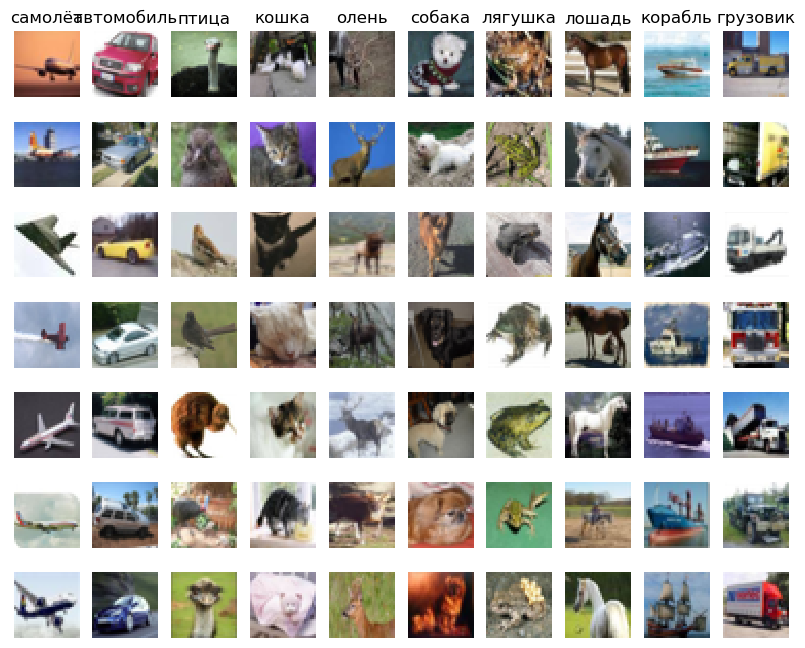

In [4]:
# Визуализируем несколько примеров из набора данных.
# Для каждого класса покажем несколько обучающих изображений.
classes = ['самолёт', 'автомобиль', 'птица', 'кошка', 'олень', 'собака', 'лягушка', 'лошадь', 'корабль', 'грузовик']
num_classes = len(classes)
samples_per_class = 7
for y, cls in enumerate(classes):
    idxs = np.flatnonzero(y_train == y)
    idxs = np.random.choice(idxs, samples_per_class, replace=False)
    for i, idx in enumerate(idxs):
        plt_idx = i * num_classes + y + 1
        plt.subplot(samples_per_class, num_classes, plt_idx)
        plt.imshow(X_train[idx].astype('uint8'))
        plt.axis('off')
        if i == 0:
            plt.title(cls)
plt.show()

In [5]:
# Разбиваем данные на обучающую, валидационную и тестовую выборки. Кроме того,
# создадим небольшую отладочную (dev) выборку как подмножество обучающих данных:
# на ней удобно отлаживать код, потому что он будет выполняться быстрее.
num_training = 49000
num_validation = 1000
num_test = 1000
num_dev = 500

# Валидационная выборка — это num_validation объектов из исходной
# обучающей выборки.
mask = range(num_training, num_training + num_validation)
X_val = X_train[mask]
y_val = y_train[mask]

# Обучающая выборка — это первые num_training объектов исходной
# обучающей выборки.
mask = range(num_training)
X_train = X_train[mask]
y_train = y_train[mask]

# Также создадим отладочную (dev) выборку — небольшое подмножество
# обучающей выборки.
mask = np.random.choice(num_training, num_dev, replace=False)
X_dev = X_train[mask]
y_dev = y_train[mask]

# В качестве тестовой выборки берём первые num_test объектов исходной
# тестовой выборки.
mask = range(num_test)
X_test = X_test[mask]
y_test = y_test[mask]

print('Форма обучающих данных: ', X_train.shape)
print('Форма обучающих меток: ', y_train.shape)
print('Форма валидационных данных: ', X_val.shape)
print('Форма валидационных меток: ', y_val.shape)
print('Форма тестовых данных: ', X_test.shape)
print('Форма тестовых меток: ', y_test.shape)

Форма обучающих данных:  (49000, 32, 32, 3)
Форма обучающих меток:  (49000,)
Форма валидационных данных:  (1000, 32, 32, 3)
Форма валидационных меток:  (1000,)
Форма тестовых данных:  (1000, 32, 32, 3)
Форма тестовых меток:  (1000,)


In [6]:
# Предобработка: вытягиваем каждое изображение в строку
X_train = np.reshape(X_train, (X_train.shape[0], -1))
X_val = np.reshape(X_val, (X_val.shape[0], -1))
X_test = np.reshape(X_test, (X_test.shape[0], -1))
X_dev = np.reshape(X_dev, (X_dev.shape[0], -1))

# Для быстрой проверки выведем формы массивов данных
print('Форма обучающих данных: ', X_train.shape)
print('Форма валидационных данных: ', X_val.shape)
print('Форма тестовых данных: ', X_test.shape)
print('Форма отладочных (dev) данных: ', X_dev.shape)

Форма обучающих данных:  (49000, 3072)
Форма валидационных данных:  (1000, 3072)
Форма тестовых данных:  (1000, 3072)
Форма отладочных (dev) данных:  (500, 3072)


[130.64189796 135.98173469 132.47391837 130.05569388 135.34804082
 131.75402041 130.96055102 136.14328571 132.47636735 131.48467347]


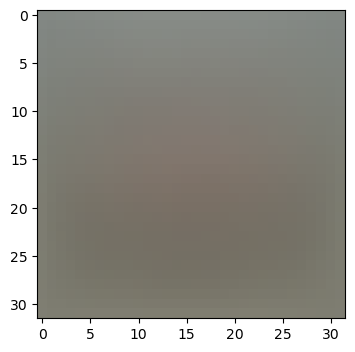

(49000, 3073) (1000, 3073) (1000, 3073) (500, 3073)


In [7]:
# Предобработка: вычитаем среднее изображение
# шаг 1: вычисляем среднее изображение по обучающим данным
mean_image = np.mean(X_train, axis=0)
print(mean_image[:10]) # выводим несколько первых элементов
plt.figure(figsize=(4,4))
plt.imshow(mean_image.reshape((32,32,3)).astype('uint8')) # визуализируем среднее изображение
plt.show()

# шаг 2: вычитаем среднее изображение из данных всех выборок
X_train -= mean_image
X_val -= mean_image
X_test -= mean_image
X_dev -= mean_image

# шаг 3: дописываем к данным столбец из единиц для смещения («трюк со смещением»,
# bias trick), чтобы классификатору нужно было оптимизировать только одну
# матрицу весов W.
X_train = np.hstack([X_train, np.ones((X_train.shape[0], 1))])
X_val = np.hstack([X_val, np.ones((X_val.shape[0], 1))])
X_test = np.hstack([X_test, np.ones((X_test.shape[0], 1))])
X_dev = np.hstack([X_dev, np.ones((X_dev.shape[0], 1))])

print(X_train.shape, X_val.shape, X_test.shape, X_dev.shape)

## Классификатор Softmax

Весь код для этого раздела пишется в файле `dlcv/classifiers/softmax.py`.

В этом файле уже есть функция `softmax_loss_naive`, в которой вычисление значения функции потерь softmax с помощью циклов `for` написано за вас; градиент вы допишете в ней ниже.

In [8]:
# Проверим наивную реализацию функции потерь (значение потерь в ней уже вычисляется):
from dlcv.classifiers.softmax import softmax_loss_naive
import time

# генерируем случайную матрицу весов классификатора Softmax из маленьких чисел
W = np.random.randn(3073, 10) * 0.0001

loss, grad = softmax_loss_naive(W, X_dev, y_dev, 0.000005)

# Грубая проверка на здравый смысл: значение потерь должно быть близко к -log(0.1).
print('потери: %f' % loss)
print('ожидаемое значение, -log(0.1): %f' % (-np.log(0.1)))

потери: 2.348129
ожидаемое значение, -log(0.1): 2.302585


**Вопрос 1**

Почему следует ожидать, что значение потерь окажется близким к -log(0.1)? Объясните кратко.

**Ваш ответ:** Так как веса в начале очень маленькие, классификатор почти не различает классы и выдаёт вероятность около 0.1 для каждого из 10 классов. Softmax loss равен -log вероятности правильного класса, поэтому потери должны быть близки к -log(0.1).


Сейчас градиент `grad`, который возвращает функция выше, целиком состоит из нулей. Выведите формулу градиента функции потерь softmax и реализуйте её прямо внутри функции `softmax_loss_naive`. Удобнее всего встроить новый код в уже написанный код этой функции.

Чтобы убедиться, что градиент реализован правильно, можно численно оценить градиент функции потерь и сравнить эту оценку с градиентом, который вычислили вы. Код, который это делает, уже готов:

In [9]:
# Когда вы реализуете градиент, пересчитайте его с помощью кода ниже
# и выполните проверку градиента (gradient check) готовой функцией

# Вычисляем значение потерь и градиент в точке W.
loss, grad = softmax_loss_naive(W, X_dev, y_dev, 0.0)

# Численно вычисляем градиент по нескольким случайно выбранным координатам и
# сравниваем его с вычисленным вами аналитическим градиентом. Числа должны
# почти точно совпадать по всем координатам.
from dlcv.gradient_check import grad_check_sparse
f = lambda w: softmax_loss_naive(w, X_dev, y_dev, 0.0)[0]
grad_numerical = grad_check_sparse(f, W, grad)

# ещё раз проверяем градиент, теперь с включённой регуляризацией.
# вы ведь не забыли про градиент регуляризации?
loss, grad = softmax_loss_naive(W, X_dev, y_dev, 5e1)
f = lambda w: softmax_loss_naive(w, X_dev, y_dev, 5e1)[0]
grad_numerical = grad_check_sparse(f, W, grad)

численный: 2.477146 аналитический: 2.477146, относительная ошибка: 2.585368e-08
численный: 0.597588 аналитический: 0.597588, относительная ошибка: 1.936409e-08
численный: -2.557260 аналитический: -2.557260, относительная ошибка: 5.615706e-09
численный: -0.458769 аналитический: -0.458769, относительная ошибка: 4.311263e-10
численный: 2.198060 аналитический: 2.198060, относительная ошибка: 8.149934e-09
численный: -0.671224 аналитический: -0.671224, относительная ошибка: 6.887601e-08
численный: -0.980741 аналитический: -0.980741, относительная ошибка: 5.137438e-08
численный: 0.543114 аналитический: 0.543114, относительная ошибка: 1.403302e-07
численный: 1.170459 аналитический: 1.170459, относительная ошибка: 6.563588e-08
численный: 3.476541 аналитический: 3.476541, относительная ошибка: 1.770818e-08
численный: -2.968072 аналитический: -2.968072, относительная ошибка: 5.981300e-10
численный: -1.957397 аналитический: -1.957397, относительная ошибка: 1.859131e-08
численный: 3.927144 аналитич

**Вопрос 2**

Для функции потерь softmax проверка градиента работает надёжно, но для функции потерь SVM иногда бывает, что по какой-нибудь координате численный и аналитический градиенты не совпадают точно. Чем может быть вызвано такое расхождение? Стоит ли из-за него беспокоиться? Приведите простой одномерный пример, в котором проверка градиента для функции потерь SVM может не пройти. Как изменение зазора (margin) повлияет на то, как часто это происходит?

Отметим, что функция потерь SVM (многоклассовая hinge loss) для объекта $(x_i, y_i)$ определяется так: $$L_i = \sum_{j\ne y_i}\max(0, s_j - s_{y_i} + \Delta)$$ где $j$ пробегает все классы, кроме правильного класса $y_i$, а $s_j$ — оценка (score) классификатора для $j$-го класса; $\Delta$ — скалярный зазор (margin). Иными словами, штраф за неправильный класс $j$ равен нулю, если оценка правильного класса больше его оценки хотя бы на $\Delta$, и положителен в противном случае.

*Подсказка: функция потерь SVM, строго говоря, не является дифференцируемой.*

**Ваш ответ:** Расхождение может возникать из-за того, что функция потерь SVM содержит слагаемые вида

$$
\max(0, s_j - s_{y_i} + \Delta)
$$

и не является дифференцируемой в точках, где

$$
s_j - s_{y_i} + \Delta = 0.
$$

В такой точке штраф ровно переходит из нуля в положительное значение, поэтому у функции есть излом. Аналитический градиент обычно использует один из возможных субградиентов, а численный градиент через конечные разности может брать значения функции по разные стороны излома. Из-за этого они могут не совпасть. Если расхождение возникает только в таких граничных точках, обычно это не является проблемой.

Простой одномерный пример:

$$
f(x) = \max(0, x).
$$

В точке \(x = 0\) производная не определена. Центральная разность даёт

$$
\frac{f(h) - f(-h)}{2h}
=
\frac{h - 0}{2h}
=
\frac{1}{2},
$$

а выбранный аналитический субградиент может быть равен \(0\) или \(1\).

Изменение margin $\Delta$ сдвигает положение точек, где выполняется равенство

$$
s_j - s_{y_i} + \Delta = 0.
$$

Поэтому оно может изменить то, как часто примеры оказываются рядом с изломом, но причина расхождений остаётся той же: недифференцируемость hinge loss в граничных точках.


In [10]:
# Теперь реализуйте функцию softmax_loss_vectorized; пока вычисляйте в ней
# только значение потерь, градиент реализуем чуть позже.
tic = time.time()
loss_naive, grad_naive = softmax_loss_naive(W, X_dev, y_dev, 0.000005)
toc = time.time()
print('Наивная реализация: потери %e, время вычисления %f с' % (loss_naive, toc - tic))

from dlcv.classifiers.softmax import softmax_loss_vectorized
tic = time.time()
loss_vectorized, _ = softmax_loss_vectorized(W, X_dev, y_dev, 0.000005)
toc = time.time()
print('Векторизованная реализация: потери %e, время вычисления %f с' % (loss_vectorized, toc - tic))

# Значения потерь должны совпадать, но векторизованная реализация должна работать намного быстрее.
print('разница: %f' % (loss_naive - loss_vectorized))

Наивная реализация: потери 2.348129e+00, время вычисления 0.093157 с
Векторизованная реализация: потери 2.348129e+00, время вычисления 0.002014 с
разница: -0.000000


In [11]:
# Завершите реализацию softmax_loss_vectorized: вычислите градиент функции
# потерь векторизованным способом.

# Результаты наивной и векторизованной реализаций должны совпадать, но
# векторизованная версия по-прежнему должна работать намного быстрее.
tic = time.time()
_, grad_naive = softmax_loss_naive(W, X_dev, y_dev, 0.000005)
toc = time.time()
print('Наивная реализация, потери и градиент: время вычисления %f с' % (toc - tic))

tic = time.time()
_, grad_vectorized = softmax_loss_vectorized(W, X_dev, y_dev, 0.000005)
toc = time.time()
print('Векторизованная реализация, потери и градиент: время вычисления %f с' % (toc - tic))

# Значение потерь — это одно число, поэтому результаты двух реализаций легко
# сравнить. Градиент же — матрица, поэтому для сравнения используем норму
# Фробениуса.
difference = np.linalg.norm(grad_naive - grad_vectorized, ord='fro')
print('разница: %f' % difference)

Наивная реализация, потери и градиент: время вычисления 0.088443 с
Векторизованная реализация, потери и градиент: время вычисления 0.000999 с
разница: 0.000000


### Стохастический градиентный спуск

Теперь у вас есть эффективные векторизованные выражения для функции потерь и её градиента, причём градиент совпадает с численным. Значит, всё готово к тому, чтобы минимизировать функцию потерь с помощью SGD. Код для этой части пишется в файле `dlcv/classifiers/linear_classifier.py`.

In [12]:
# Реализуйте SGD в методе LinearClassifier.train() в файле linear_classifier.py,
# а затем запустите обучение с помощью кода ниже.
from dlcv.classifiers import Softmax
softmax = Softmax()
tic = time.time()
loss_hist = softmax.train(X_train, y_train, learning_rate=1e-7, reg=2.5e4,
                      num_iters=1500, verbose=True)
toc = time.time()
print('Обучение заняло %f с' % (toc - tic))

итерация 0 / 1500: потери 779.611809
итерация 100 / 1500: потери 286.027721
итерация 200 / 1500: потери 106.039094
итерация 300 / 1500: потери 40.126133
итерация 400 / 1500: потери 16.048608
итерация 500 / 1500: потери 7.205594
итерация 600 / 1500: потери 3.900371
итерация 700 / 1500: потери 2.746068
итерация 800 / 1500: потери 2.295343
итерация 900 / 1500: потери 2.188952
итерация 1000 / 1500: потери 2.080706
итерация 1100 / 1500: потери 2.116523
итерация 1200 / 1500: потери 2.103378
итерация 1300 / 1500: потери 2.095092
итерация 1400 / 1500: потери 2.144619
Обучение заняло 3.508779 с


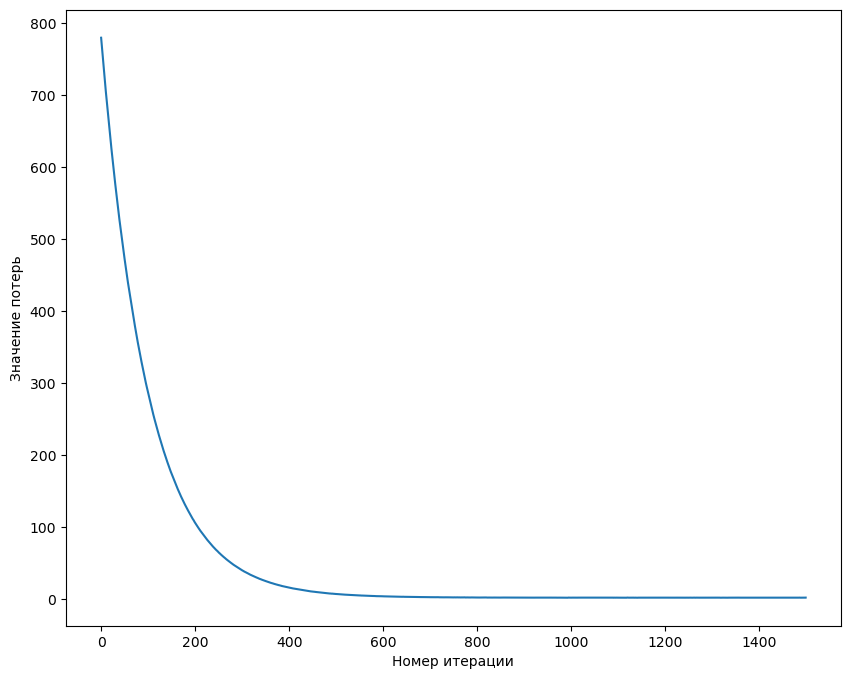

In [13]:
# Полезный приём при отладке — построить график значения потерь
# в зависимости от номера итерации:
plt.plot(loss_hist)
plt.xlabel('Номер итерации')
plt.ylabel('Значение потерь')
plt.show()

In [14]:
# Реализуйте функцию LinearClassifier.predict и оцените качество классификатора
# на обучающей и валидационной выборках.
# Точность (accuracy, доля правильных ответов) на валидационной выборке должна
# получиться около 0.34 (> 0.33).
y_train_pred = softmax.predict(X_train)
print('точность на обучающей выборке: %f' % (np.mean(y_train == y_train_pred), ))
y_val_pred = softmax.predict(X_val)
print('точность на валидационной выборке: %f' % (np.mean(y_val == y_val_pred), ))

точность на обучающей выборке: 0.332612
точность на валидационной выборке: 0.341000


In [15]:
# Сохраняем обученную модель (файл появится в папке `dlcv/saved/`).
softmax.save("softmax.npy")

softmax.npy сохранён.


In [18]:
# Используйте валидационную выборку для подбора гиперпараметров (коэффициента
# регуляризации и скорости обучения). Поэкспериментируйте с разными диапазонами
# скоростей обучения и коэффициентов регуляризации; при аккуратном подборе
# точность классификации на валидационной выборке должна получиться не ниже
# 0.36 (при удачном подборе — около 0.40).

# Примечание: во время подбора гиперпараметров могут появляться предупреждения
# RuntimeWarning (например, о переполнении — overflow). Их могут вызывать
# экстремальные значения гиперпараметров, и это не ошибка в коде.

# results — словарь, который сопоставляет кортежам вида
# (learning_rate, regularization_strength) кортежи вида
# (training_accuracy, validation_accuracy). Точность — это просто доля
# правильно классифицированных объектов.
results = {}
best_val = -1   # Наибольшая точность на валидационной выборке на данный момент.
best_softmax = None # Объект Softmax, показавший наибольшую точность на валидационной выборке.

################################################################################
# TODO:                                                                        #
# Напишите код, который выбирает лучшие гиперпараметры по валидационной        #
# выборке. Для каждой комбинации гиперпараметров обучите классификатор         #
# Softmax на обучающей выборке, вычислите его точность на обучающей и          #
# валидационной выборках и сохраните эти числа в словаре results. Кроме        #
# того, сохраните наибольшую точность на валидационной выборке в best_val,     #
# а объект Softmax, который её достигает, — в best_softmax.                    #
#                                                                              #
# Подсказка: пока вы отлаживаете код валидации, используйте небольшое          #
# значение num_iters, чтобы классификаторы обучались быстро; когда             #
# убедитесь, что код валидации работает, перезапустите его с большим           #
# значением num_iters.                                                         #
################################################################################

# Значения приведены для примера; при желании эти гиперпараметры можно изменить
learning_rates = [1e-7, 2e-7, 3e-7, 5e-7]
regularization_strengths = [1e4, 2.5e4, 5e4]

for lr in learning_rates:
    for reg in regularization_strengths:
        softmax = Softmax()


        softmax.train(
            X_train,
            y_train,
            learning_rate=lr,
            reg=reg,
            num_iters=1500,
            batch_size=200,
            verbose=False
        )

        y_train_pred = softmax.predict(X_train)
        y_val_pred = softmax.predict(X_val)


        train_accuracy = np.mean(y_train == y_train_pred)
        val_accuracy = np.mean(y_val == y_val_pred)

        results[((lr, reg))] = (train_accuracy, val_accuracy)

        if val_accuracy > best_val:
            best_val = val_accuracy
            best_softmax = softmax



# Выводим результаты.
for lr, reg in sorted(results):
    train_accuracy, val_accuracy = results[(lr, reg)]
    print('lr %e reg %e точность на обучении: %f точность на валидации: %f' % (
                lr, reg, train_accuracy, val_accuracy))

print('лучшая точность на валидационной выборке при подборе гиперпараметров: %f' % best_val)

lr 1.000000e-07 reg 1.000000e+04 точность на обучении: 0.353857 точность на валидации: 0.364000
lr 1.000000e-07 reg 2.500000e+04 точность на обучении: 0.334327 точность на валидации: 0.345000
lr 1.000000e-07 reg 5.000000e+04 точность на обучении: 0.307857 точность на валидации: 0.326000
lr 2.000000e-07 reg 1.000000e+04 точность на обучении: 0.357673 точность на валидации: 0.370000
lr 2.000000e-07 reg 2.500000e+04 точность на обучении: 0.330735 точность на валидации: 0.352000
lr 2.000000e-07 reg 5.000000e+04 точность на обучении: 0.305000 точность на валидации: 0.311000
lr 3.000000e-07 reg 1.000000e+04 точность на обучении: 0.357612 точность на валидации: 0.367000
lr 3.000000e-07 reg 2.500000e+04 точность на обучении: 0.331755 точность на валидации: 0.343000
lr 3.000000e-07 reg 5.000000e+04 точность на обучении: 0.302245 точность на валидации: 0.305000
lr 5.000000e-07 reg 1.000000e+04 точность на обучении: 0.353816 точность на валидации: 0.362000
lr 5.000000e-07 reg 2.500000e+04 точност

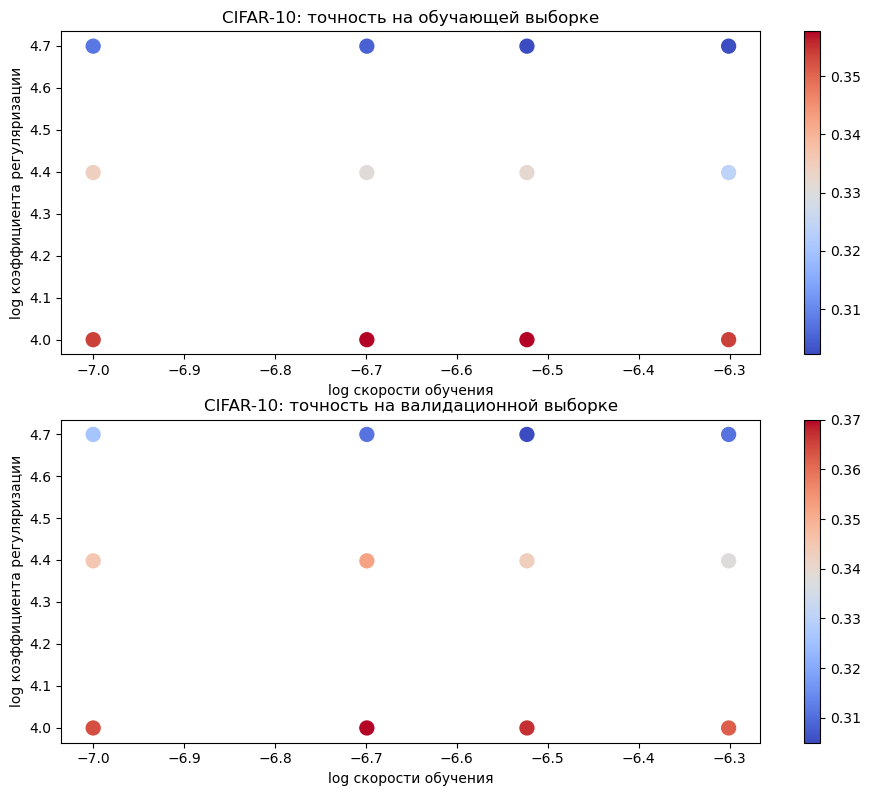

In [19]:
# Визуализируем результаты подбора гиперпараметров
import math
x_scatter = [math.log10(x[0]) for x in results]
y_scatter = [math.log10(x[1]) for x in results]

# график точности на обучающей выборке
marker_size = 100
colors = [results[x][0] for x in results]
plt.subplot(2, 1, 1)
plt.tight_layout(pad=3)
plt.scatter(x_scatter, y_scatter, marker_size, c=colors, cmap=plt.cm.coolwarm)
plt.colorbar()
plt.xlabel('log скорости обучения')
plt.ylabel('log коэффициента регуляризации')
plt.title('CIFAR-10: точность на обучающей выборке')

# график точности на валидационной выборке
colors = [results[x][1] for x in results] # размер маркеров по умолчанию — 20
plt.subplot(2, 1, 2)
plt.scatter(x_scatter, y_scatter, marker_size, c=colors, cmap=plt.cm.coolwarm)
plt.colorbar()
plt.xlabel('log скорости обучения')
plt.ylabel('log коэффициента регуляризации')
plt.title('CIFAR-10: точность на валидационной выборке')
plt.show()

In [20]:
# Оцениваем лучший классификатор Softmax на тестовой выборке
y_test_pred = best_softmax.predict(X_test)
test_accuracy = np.mean(y_test == y_test_pred)
print('Классификатор Softmax на исходных пикселях, итоговая точность на тестовой выборке: %f' % test_accuracy)

Классификатор Softmax на исходных пикселях, итоговая точность на тестовой выборке: 0.369000


In [21]:
# Сохраняем лучшую модель Softmax (файл появится в папке `dlcv/saved/`).
best_softmax.save("best_softmax.npy")

best_softmax.npy сохранён.


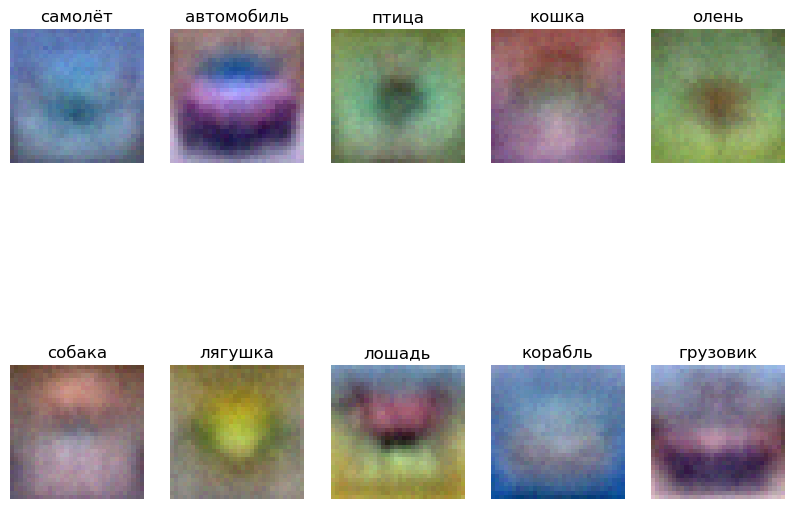

In [23]:
# Визуализируем обученные веса для каждого класса.
# В зависимости от выбранных скорости обучения и коэффициента регуляризации
# картинки могут получиться как наглядными, так и не очень.
w = best_softmax.W[:-1,:] # отбрасываем смещение
w = w.reshape(32, 32, 3, 10)
w_min, w_max = np.min(w), np.max(w)
classes = ['самолёт', 'автомобиль', 'птица', 'кошка', 'олень', 'собака', 'лягушка', 'лошадь', 'корабль', 'грузовик']
for i in range(10):
    plt.subplot(2, 5, i + 1)

    # Масштабируем веса в диапазон от 0 до 255
    wimg = 255.0 * (w[:, :, :, i].squeeze() - w_min) / (w_max - w_min)
    plt.imshow(wimg.astype('uint8'))
    plt.axis('off')
    plt.title(classes[i])
plt.show()

**Вопрос 3**

Опишите, как выглядят визуализированные веса вашего классификатора Softmax, и кратко объясните, почему они выглядят именно так.

**Ваш ответ:** Визуализированные веса выглядят как размытые цветовые шаблоны классов. Для некоторых классов заметны характерные признаки: у самолёта и корабля много синего цвета, что похоже на небо или воду; у автомобиля, лошади и грузовика видны горизонтальные тёмные области, похожие на силуэт объекта; у лягушки и оленя заметны зелёные/жёлтые оттенки, связанные с типичным фоном или окраской. При этом изображения остаются очень размытыми и шумными, без чётких деталей объектов.

Так происходит потому, что Softmax-классификатор является линейной моделью. Для каждого класса он учит один набор весов по исходным пикселям, поэтому веса отражают усреднённые цветовые и пространственные закономерности обучающих изображений. Модель не выделяет сложные признаки формы, поэтому визуализации похожи не на настоящие объекты, а на усреднённые шаблоны.


**Вопрос 4** — *Верно или неверно*

Пусть общее значение функции потерь на обучающей выборке определяется как сумма потерь по всем обучающим примерам. Можно добавить в обучающую выборку новый объект так, что потери softmax изменятся, а потери SVM останутся прежними. (Определение функции потерь SVM см. в вопросе 2.)

**Ваш ответ:** Верно

**Ваше объяснение:** Можно добавить объект, для которого SVM loss равен нулю. Например, если score правильного класса больше scores всех неправильных классов хотя бы на margin:

$$
s_{y_i} > s_j + \Delta \quad \text{для всех } j \ne y_i,
$$

то для каждого неправильного класса:

$$
\max(0, s_j - s_{y_i} + \Delta) = 0.
$$

Значит, суммарные потери SVM не изменятся.

Но softmax loss для этого же объекта всё равно будет положительным:

$$
L_i = -\log p_{y_i}.
$$

При конечных score вероятность правильного класса $p_{y_i}$ может быть очень близка к $1$, но не равна $1$ точно. Поэтому:

$$
-\log p_{y_i} > 0.
$$

Следовательно, суммарные потери softmax изменятся, а суммарные потери SVM останутся прежними.